# 01 – GFlash-like formula for the electron shower

## 1. Introduction

In the detector metal an electron starts an **electromagnetic cascade**: it radiates a photon, the photon creates an electron–positron pair, these
radiate again, and so on. The number of particles first grows quickly, then, once the individual particle energies drop below a
critical value, the cascade dies out. It is like a **drop or a firework plume**: it develops quickly, is thickest at its maximum,
then thins out.

The GFlash parametrisation (Grindhammer–Peters, see reference below) describes this with two simple functions:

$$\rho(r, z' \mid p) = \underbrace{L(z' \mid p)}_{\text{depth profile}} \cdot \underbrace{T(r \mid z', p)}_{\text{cross-section}}$$

- **Depth, $L$:** Gamma distribution, $L \propto s^{\alpha-1} e^{-(\alpha-1)s/t_{max}}$, where $s = z' - z_0$. The position of the maximum is $t_{max}$, which grows
  logarithmically with energy ($t_{max} \approx X_0[\ln(E/E_c) - 0.5]$).
- **Cross-section, $T$:** narrow core and wide tail, with two Cauchy terms. The scale is the Molière radius (approx. 17 mm in iron), much smaller than the cell (~48 mm).

**Coordinates (shower-local coordinates):**
- $z'$ (`z_local`): depth along the direction of incidence, in mm. The origin is the centroid of the first hit layer, so for oblique incidence negative $z'$ also occurs.
- $r = \sqrt{x_{local}^2 + y_{local}^2}$: the hit's **perpendicular distance from the shower axis** (the line of the incoming particle), in mm.
  The shape is assumed cylindrically symmetric, so the azimuthal angle does not appear. 2D plots show $r$ mirrored ($\pm r$).
- The measured $r$ is that of the **cell centre** (cell ~48 mm), so the measured distribution is coarse; the model is compared to it after averaging over the cell.

Every parameter is linear in $\ln p$; the lateral parameters may also vary with depth. About 15 parameters in total.
This formula is fitted **directly to the data**; it is the physical reference (baseline) for the electron.

**Reference:**
- G. Grindhammer, S. Peters: *The Parameterized Simulation of Electromagnetic Showers in Homogeneous and Sampling Calorimeters*,
  Proc. Int. Conf. on Monte Carlo Simulation in High Energy and Nuclear Physics (MC 93), Tallahassee, 1993;
  [arXiv:hep-ex/0001020](https://arxiv.org/abs/hep-ex/0001020). This is the primary source of the parametrisation.
- Predecessor: G. Grindhammer, M. Rudowicz, S. Peters: *The fast simulation of electromagnetic and hadronic showers*,
  Nucl. Instrum. Meth. A 290 (1990) 469, [doi:10.1016/0168-9002(90)90566-O](https://doi.org/10.1016/0168-9002(90)90566-O).

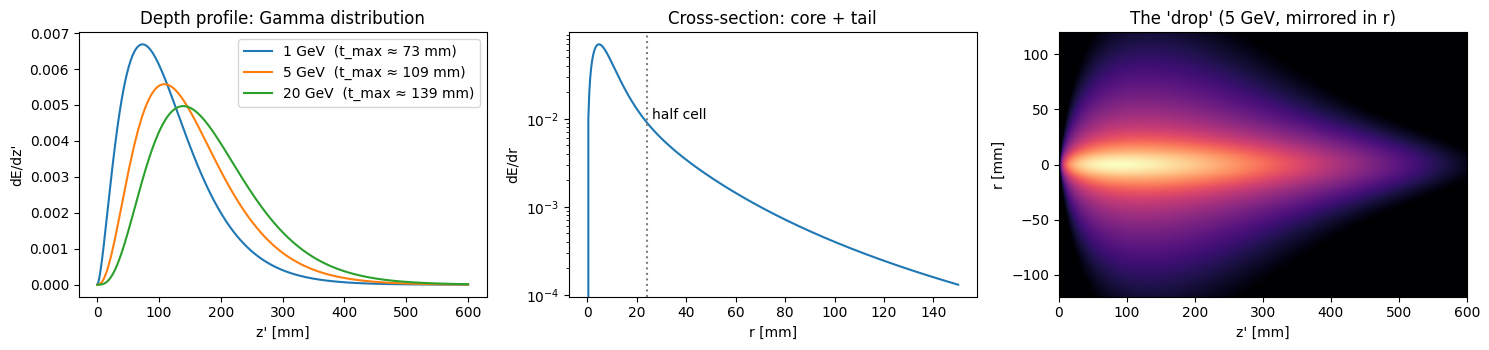

In [1]:
import numpy as np, matplotlib.pyplot as plt

X0, EC = 22.0, 0.0217                       # illustrative: radiation length [mm], critical energy [GeV]
z = np.linspace(0.1, 600, 400)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for E in (1, 5, 20):
    tmax = X0 * (np.log(E / EC) - 0.5); b = 0.5 / X0; a = 1 + b * tmax
    L = z ** (a - 1) * np.exp(-b * z)
    ax[0].plot(z, L / np.trapezoid(L, z), label=f"{E} GeV  (t_max ≈ {tmax:.0f} mm)")
ax[0].set(title="Depth profile: Gamma distribution", xlabel="z' [mm]", ylabel="dE/dz'"); ax[0].legend()
r = np.linspace(0, 150, 400); Rc, Rt, pc = 8.0, 35.0, 0.85
T = (pc * Rc**2 / (r**2 + Rc**2)**2 + (1 - pc) * Rt**2 / (r**2 + Rt**2)**2) / np.pi
ax[1].semilogy(r, 2 * np.pi * r * T); ax[1].axvline(24, ls=":", c="grey"); ax[1].text(26, 1e-2, "half cell")
ax[1].set(title="Cross-section: core + tail", xlabel="r [mm]", ylabel="dE/dr")
Z, R = np.meshgrid(z, np.linspace(-120, 120, 241))
tmax = X0 * (np.log(5 / EC) - 0.5); b = 0.5 / X0; a = 1 + b * tmax
rc = Rc * (1 + Z / 250)
rho = Z ** (a - 1) * np.exp(-b * Z) * (pc * rc**2 / (R**2 + rc**2)**2 + (1 - pc) * (4 * rc)**2 / (R**2 + (4 * rc)**2)**2)
ax[2].imshow(np.log10(rho + 1e-30), extent=[0, 600, -120, 120], aspect="auto", origin="lower", cmap="magma",
             vmin=np.log10(rho.max()) - 4)
ax[2].set(title="The 'drop' (5 GeV, mirrored in r)", xlabel="z' [mm]", ylabel="r [mm]")
plt.tight_layout(); plt.show()

## 2. Loading data

In [2]:
PARTICLES = ['electron']
DATA_DIR = "../../data/simulations/regression-electron/"          # location of the CSVs
OUT_DIR = "results"        # models and exports go here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-electron/ | output: results


In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

electron: 99995 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69996, val 14999, test 15000

===== electron =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11436422 entries, 0 to 11436421
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi            

,count,mean,std,min,25%,50%,75%,max
event_number,11436422.0,1.048876e+05,6.064561e+04,0.000000e+00,5.242900e+04,1.046690e+05,1.574530e+05,2.099990e+05
cellID,11436422.0,1.333742e+09,1.039108e+09,4.212000e+03,5.748668e+08,1.136943e+09,2.152149e+09,5.063301e+09
x,11436422.0,1.152600e+00,1.275030e+03,-2.596035e+03,-9.837540e+02,3.040900e+01,9.887540e+02,2.601035e+03
y,11436422.0,-4.532280e+00,1.274187e+03,-2.599800e+03,-9.838000e+02,-2.620000e+01,9.838000e+02,2.599800e+03
z,11436422.0,3.827699e+03,1.244528e+02,3.662400e+03,3.744400e+03,3.805900e+03,3.887900e+03,4.871900e+03
x_local,11436422.0,-3.327809e+00,8.815675e+01,-4.059289e+03,-4.077562e+01,-3.618190e+00,3.370563e+01,1.906138e+03
y_local,11436422.0,2.443006e-02,7.864957e+01,-2.458475e+03,-3.993694e+01,0.000000e+00,3.998249e+01,2.604588e+03
z_local,11436422.0,1.773651e+02,1.277168e+02,-2.891128e+03,8.518457e+01,1.594890e+02,2.478127e+02,1.516132e+03
x_trans,11436422.0,-4.924299e-01,1.009526e+02,-4.312513e+03,-5.151632e+01,0.000000e+00,5.133581e+01,4.081322e+03
y_trans,11436422.0,-2.044345e-01,1.005016e+02,-3.936125e+03,-5.129690e+01,0.000000e+00,5.125513e+01,4.848162e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,70485,29940084,31.983999,-882.799988,3662.399902,-50.890334,56.424332,-12.768919,57.538069,51.243998,...,0.000023,12.900945,10.534635,0.245835,-1.592273,10,gamma,1,e+,e-
1,112266,625584500,-1387.531982,-1185.800049,3887.899902,-35.797512,6.624244,232.702962,-47.734647,-48.447546,...,0.000207,14.417011,14.137709,0.444255,-2.446334,14,gamma,1,e-,e-
2,158539,1610801268,-430.761993,1488.800049,3723.899902,31.214213,36.340932,79.157411,-50.866447,46.810689,...,0.009759,13.415966,18.627253,0.387387,1.844146,18,e+,1,gamma,gamma;gamma;gamma;gamma;gamma
3,38079,562383220,1695.364990,430.200012,3682.899902,81.715416,-27.612063,59.755805,102.907916,-0.549724,...,0.000112,13.918079,7.799625,0.427491,0.266301,7,e-,1,e-,NaN
4,106394,1623446900,435.761993,1084.800049,3723.899902,-1.097030,-54.012457,64.099259,56.964273,-0.292622,...,0.000003,13.282524,19.222589,0.303365,1.242286,19,e+,1,gamma,gamma;gamma;e-;gamma;gamma;e-;gamma;gamma;gamm...


## 3. The model

The formula is the common notebook's `Formula` class: longitudinal part `gamma`, lateral part `core_tail`; the parameters are
**first-degree** polynomials in $\ln p$, and the lateral parameters also have a depth slope.
Initial values are estimated from the data: mean depth, depth spread, median radius.

### What is fitted, and what affects the fit?

**Fitted features (in the likelihood):**
- **Position:** `x_local, y_local, z_local` → $z' =$ `z_local`, $r = \sqrt{x_{local}^2 + y_{local}^2}$. The formula sees only these two coordinates.
- **Weight:** `energy`, normalised to 1 per event ($w_i$). The fit seeks the energy-weighted **mean shape**; every event counts equally.
- **Condition:** `incoming_momentum` → $\ln p$. Every formula parameter is a polynomial in $\ln p$, so a single fit gives the shape for all momenta.
- **Grouping:** `event_number`: normalisation and NLL are computed per event.

**What affects the fit but is not a fitted target:**
- `incoming_theta`, `incoming_phi` → rotation: used to rotate the detector cell into the shower frame for the convolution.
- `z`, `z_trans` (+ `incoming_theta`) → the detector back face along the axis ($z_b$). The likelihood normalisation only considers the part in front of the back face; the shape beyond it is not constrained by data.
- `x`, `y`, `z` → geometry: cell size (~48 mm) and layer spacing (~20.5 mm). This is how much the formula is "smeared" before comparison with the data.
- **Cuts:** `earliest_contribution_time` < 100 ns, $Z_{MIN} \le z' \le Z_{MAX}$, $r < R_{MAX}$.
- `incoming_momentum_bin` → only needed for stratifying the train/val/test split.
- **Initial values** (`init_from`): from the training hits' $z'$, $r$, $w$ (weighted mean depth, depth spread, median radius).
- **Training:** Adam optimiser (`lr`), early stopping on the validation NLL (`patience=15`). No smoothness penalty, since the formula is smooth by construction.

In [4]:
data = DATA["electron"]
h = data["train"].hits()
model = Formula("gamma", "core_tail", degree=1).init_from(h.z.values, h.r.values, h.w.values).to(DEVICE)
print("parameters:", model.n_params())
display(Markdown(model.describe("Initial values")))

parameters: 15


/tmp/ipykernel_322050/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### Initial values

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-20 +0\,L$ | – |
| `log_tmax` | $+3.953 +0\,L$ | – |
| `log_am1` | $-0.3489 +0\,L$ | – |
| `log_rc` | $+2.445 +0\,L$ | +0 |
| `log_ratio` | $+1.099 +0\,L$ | +0 |
| `logit_pc` | $+0.85 +0\,L$ | +0 |

Number of parameters: **15**

## 4. Training

Training minimises the common likelihood: the formula, convolved with the detector cell, is compared with the measured hits.
The model is saved to `results/electron/gflash.pt`; if training has already run, it is just loaded.

Settings: `epochs=150`, `lr=0.03`, electron data only. Here the cell size (~48 mm) is much larger than the Molière radius, so the core radius (`rc`) is constrained mainly by the convolution and the energy sharing within the cell, not directly by the hits' $r$.

loaded finished model from results/electron/gflash.pt


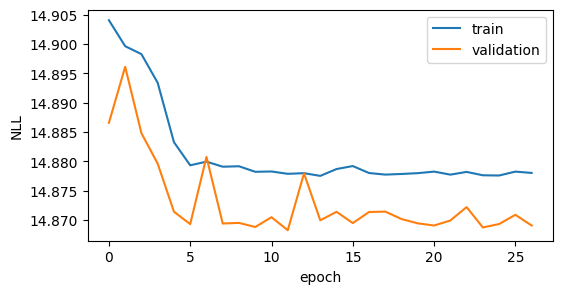

In [5]:
hist = fit(model, data, f"{OUT_DIR}/electron/gflash.pt", epochs=150, lr=0.03)
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 4b. Selecting the degree of the $\ln p$ polynomial

Besides the $n=1$ model above, we also fit degrees $n = 1 \dots 6$ (`select_degree`; protocol in section 7 of the common notebook).
The degree is chosen on the **validation** set; the **test** set only measures the final model. Models are saved to `results/electron/gflash_n<n>.pt`;
a completed training is just loaded.

**What to look for:** the train curve always decreases with $n$. If the validation curve flattens or turns back, further
degrees only fit noise.

--- degree 1 ---
loaded finished model from results/electron/gflash_n1.pt


--- degree 2 ---
loaded finished model from results/electron/gflash_n2.pt


--- degree 3 ---
loaded finished model from results/electron/gflash_n3.pt


--- degree 4 ---
loaded finished model from results/electron/gflash_n4.pt


--- degree 5 ---
loaded finished model from results/electron/gflash_n5.pt


--- degree 6 ---
loaded finished model from results/electron/gflash_n6.pt


lowest validation NLL: n* = 4;  chosen by the 1-SE rule: n = 4


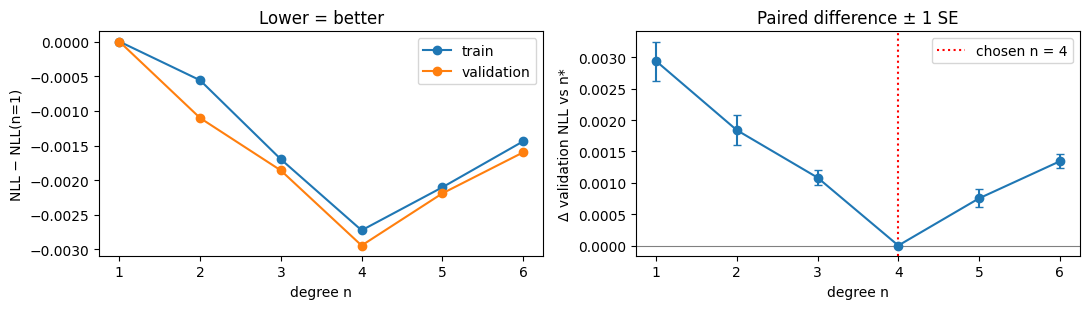

,params,train NLL,val NLL,epochs,Δval vs n*,SE,chosen
n,,,,,,,
1,15,14.8349,14.8284,64,0.0029,0.0003,
2,21,14.8344,14.8273,21,0.0018,0.0002,
3,27,14.8332,14.8266,16,0.0011,0.0001,
4,33,14.8322,14.8255,25,0.0000,0.0000,◀
5,39,14.8328,14.8262,22,0.0008,0.0001,
6,45,14.8335,14.8268,16,0.0013,0.0001,


chosen degree: 4 | test NLL n=1: 14.8519 | chosen: 14.8479


In [6]:
model_n1 = model
model, DEGREE_TABLE, DEGREE_MODELS = select_degree("gamma", "core_tail", data, "electron", "gflash", degrees=range(1, 7),
                                                   epochs=150, lr=0.03)
display(DEGREE_TABLE.round(4))
print("chosen degree:", model.degree, "| test NLL n=1:", round(float(test_nll(model_n1, data["test"]).mean()), 4),
      "| chosen:", round(float(test_nll(model, data["test"]).mean()), 4))

## 6. Results

**What to look for:**
- **Profiles:** how well the black (data) and blue (model) curves overlap at different momenta. For the electron the depth profile
  matters more; the lateral profile is largely set by the cell size.
- **Parameters:** `tmax` (position of the maximum) should grow with momentum; the core radius (`rc`) should be much smaller than the cell.
- **3D:** the body should be "drop"-shaped, longer and thicker with increasing momentum.

### The fitted GFlash formula

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=(\ln(p/\mathrm{GeV}) +0.7609)/3.757$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-15.21 +5.797\,L -1.624\,L^2 -1.35\,L^3 +0.6446\,L^4$ | – |
| `log_tmax` | $+3.91 +1.369\,L -0.6749\,L^2 -0.003854\,L^3 +0.02245\,L^4$ | – |
| `log_am1` | $-0.3275 -0.09391\,L +0.3962\,L^2 -0.2607\,L^3 +0.09396\,L^4$ | – |
| `log_rc` | $+2.664 -0.2264\,L -0.2412\,L^2 +0.392\,L^3 -0.1934\,L^4$ | +3.293 |
| `log_ratio` | $+8.556 +0.02095\,L -0.4767\,L^2 -0.04249\,L^3 +0.08896\,L^4$ | -6.595 |
| `logit_pc` | $-2.135 +2.836\,L +1.438\,L^2 -0.05146\,L^3 -0.3319\,L^4$ | -10.68 |

Number of parameters: **33**

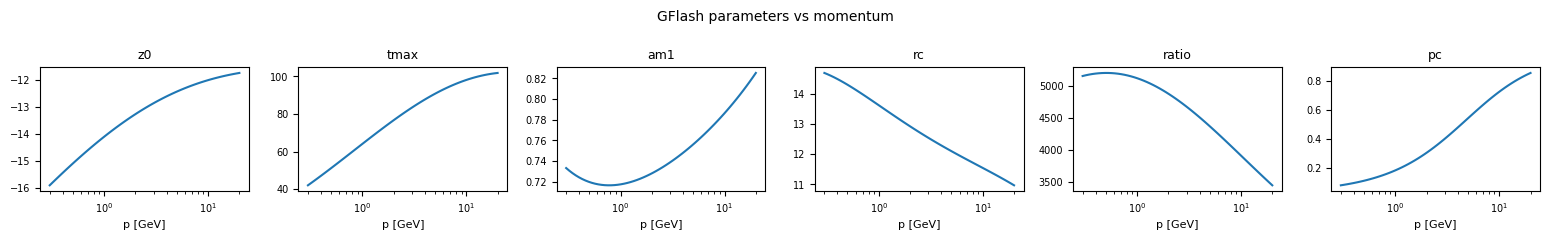

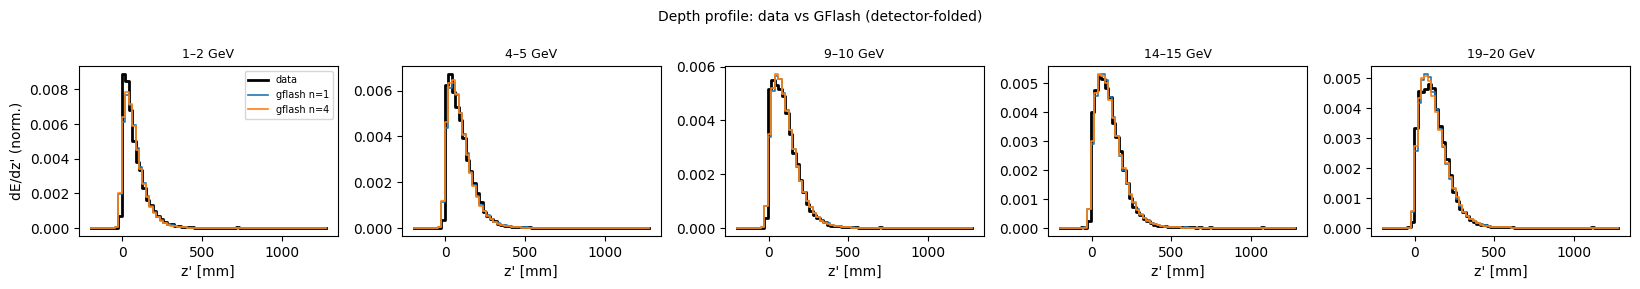

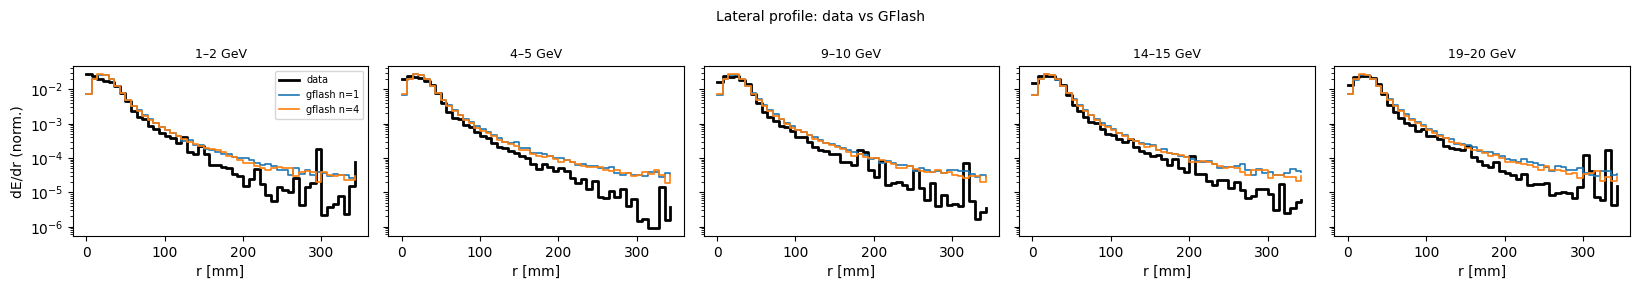

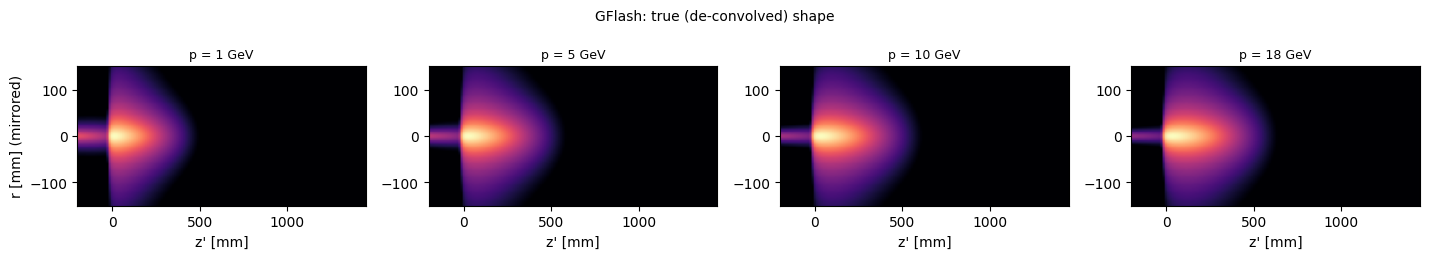

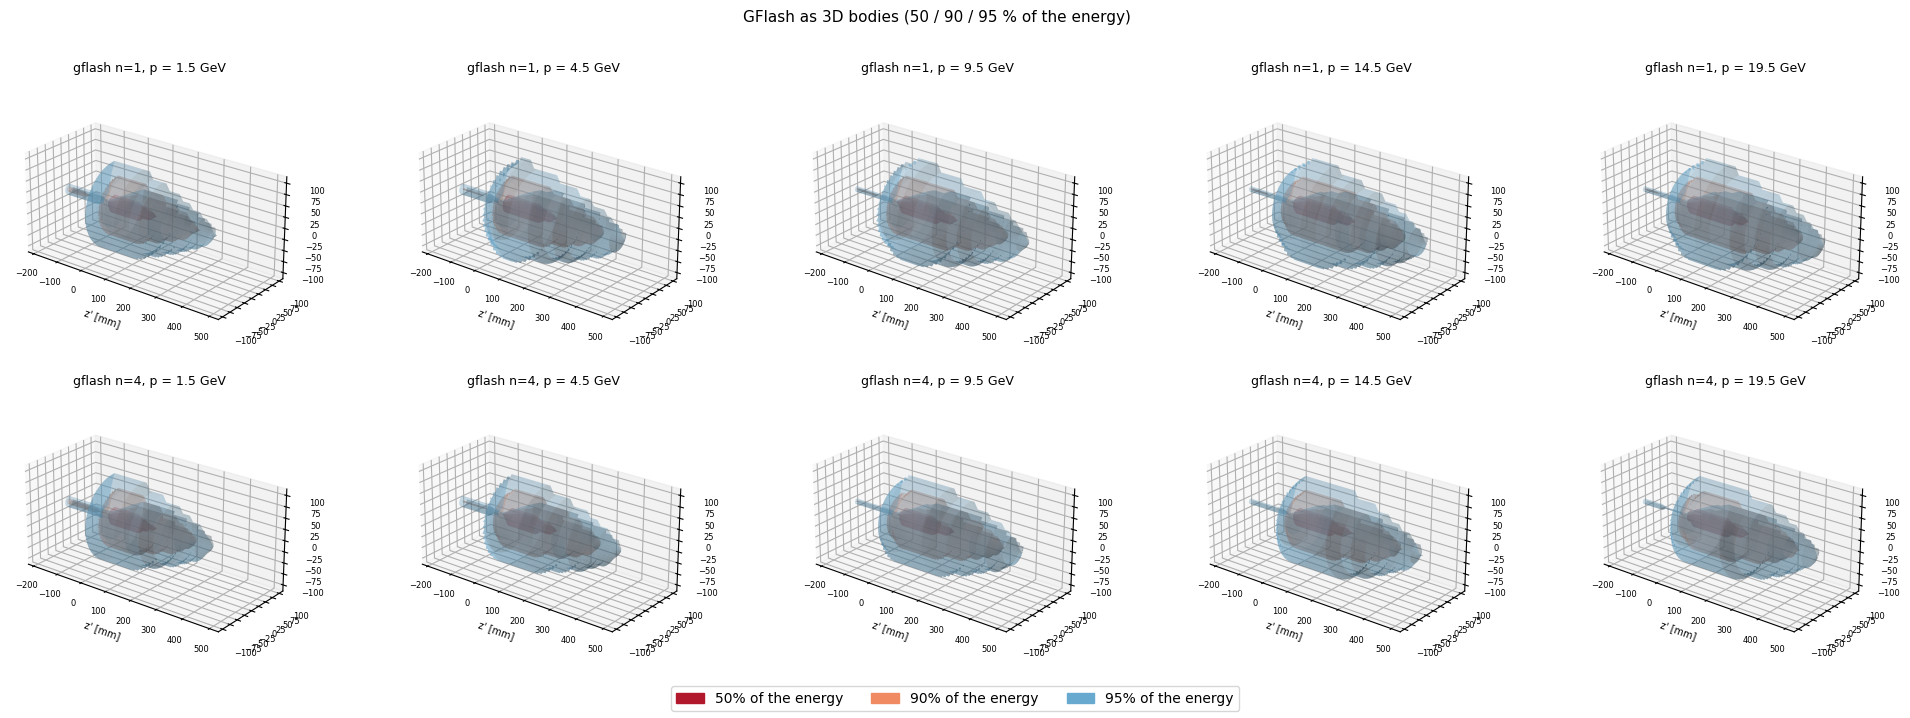

exported electron/gflash: test NLL = 14.8479


In [7]:
display(Markdown(model.describe("The fitted GFlash formula")))
formula_curves(model, "GFlash parameters vs momentum")
samples = {"gflash n=1": sample_folded(model_n1, data["test"]), f"gflash n={model.degree}": sample_folded(model, data["test"])}
hits = data["test"].hits()
profile_plot(hits, samples, "z", "Depth profile: data vs GFlash (detector-folded)")
profile_plot(hits, samples, "r", "Lateral profile: data vs GFlash")
shape_map(model, title="GFlash: true (de-convolved) shape")
bodies_3d({"gflash n=1": model_n1, f"gflash n={model.degree}": model}, title="GFlash as 3D bodies (50 / 90 / 95 % of the energy)")
export("electron", "gflash", model, data, model.describe("GFlash (elektron baseline)"))